In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving loan_prediction.csv to loan_prediction.csv


In [3]:
import io

filename = list(uploaded.keys())[0]

df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [4]:
print(df.columns.tolist())

['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']


In [5]:
df.info()

print("\nMissing values:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
Index: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 67.2+ KB

Missing values:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Educ

In [6]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [7]:
for col in df.columns:
    if any(word in col.lower() for word in ["loan_status", "loan_approved", "approved"]):
        print("\nPossible target column:", col)
        print(df[col].value_counts(dropna=False))


Possible target column: Loan_Status
Loan_Status
Y    422
N    192
Name: count, dtype: int64


In [9]:
print(df.columns.tolist())

['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']


In [10]:
for col in df.columns:
    print(f"\nColumn: {col}")
    print(df[col].head(5).tolist())


Column: Loan_ID
['LP001002', 'LP001003', 'LP001005', 'LP001006', 'LP001008']

Column: Gender
['Male', 'Male', 'Male', 'Male', 'Male']

Column: Married
['No', 'Yes', 'Yes', 'Yes', 'No']

Column: Dependents
['0', '1', '0', '0', '0']

Column: Education
['Graduate', 'Graduate', 'Graduate', 'Not Graduate', 'Graduate']

Column: Self_Employed
['No', 'No', 'Yes', 'No', 'No']

Column: ApplicantIncome
[5849, 4583, 3000, 2583, 6000]

Column: CoapplicantIncome
[0.0, 1508.0, 0.0, 2358.0, 0.0]

Column: LoanAmount
[nan, 128.0, 66.0, 120.0, 141.0]

Column: Loan_Amount_Term
[360.0, 360.0, 360.0, 360.0, 360.0]

Column: Credit_History
[1.0, 1.0, 1.0, 1.0, 1.0]

Column: Property_Area
['Urban', 'Rural', 'Urban', 'Urban', 'Urban']

Column: Loan_Status
['Y', 'N', 'Y', 'Y', 'Y']


In [12]:
# Display all column names in your dataset
print("Dataset columns:")
print(df.columns.tolist())

Dataset columns:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']


Loan Approval Distribution:
Loan_Status
Y    422
N    192
Name: count, dtype: int64


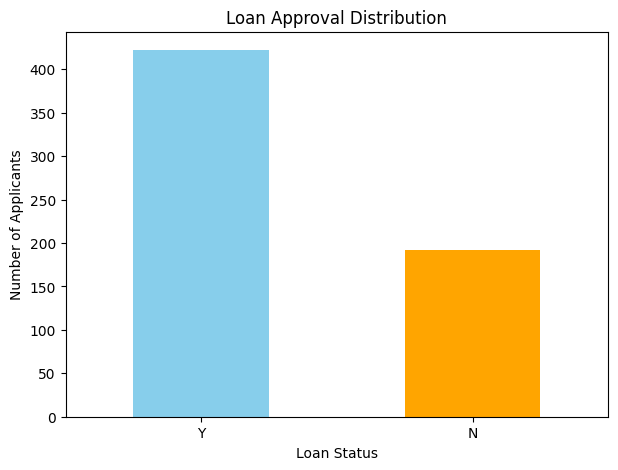

In [13]:

# Check the distribution of loan approvals
target_column = "Loan_Status"

print("Loan Approval Distribution:")
print(df[target_column].value_counts(dropna=False))

# Visualize the distribution
import matplotlib.pyplot as plt

df[target_column].value_counts().plot(
    kind="bar",
    figsize=(7, 5),
    color=["skyblue", "orange"]
)

plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=0)
plt.show()


In [14]:

# Step 1: Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

# Step 2: Check duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# Step 3: Display dataset information
print("\nDataset Information:")
df.info()

# Step 4: Check loan approval distribution
print("\nLoan Approval Counts:")
print(df["Loan_Status"].value_counts())

# Step 5: Separate input features and target
X = df.drop(columns=["Loan_ID", "Loan_Status"])
y = df["Loan_Status"]

print("\nInput features shape:", X.shape)
print("Target shape:", y.shape)

print("\nDataset preparation completed successfully!")


Missing values in each column:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

Number of duplicate rows:
0

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmou

In [15]:

# Import required libraries
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Separate numerical and categorical columns
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nPreprocessing pipeline created successfully!")


Numerical features: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']
Categorical features: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']

Training samples: 491
Testing samples: 123

Preprocessing pipeline created successfully!


In [16]:

# Import machine learning models and evaluation metrics
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Create the two machine learning pipelines
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    )
}

# Store results
results = []

# Train and evaluate each model
for model_name, model in models.items():

    print("\n" + "=" * 50)
    print("Training:", model_name)

    # Combine preprocessing and model
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    # Train the model
    pipeline.fit(X_train, y_train)

    # Make predictions
    y_pred = pipeline.predict(X_test)

    # Probability of loan approval (Y)
    y_proba = pipeline.predict_proba(X_test)[:,
        list(pipeline.named_steps["classifier"].classes_).index("Y")
    ]

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, pos_label="Y", zero_division=0)
    recall = recall_score(y_test, y_pred, pos_label="Y", zero_division=0)
    f1 = f1_score(y_test, y_pred, pos_label="Y", zero_division=0)
    roc_auc = roc_auc_score((y_test == "Y").astype(int), y_proba)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    print(f"Accuracy:  {accuracy:.3f}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall:    {recall:.3f}")
    print(f"F1-Score:  {f1:.3f}")
    print(f"ROC-AUC:   {roc_auc:.3f}")

    # Save the trained pipeline
    models[model_name] = pipeline

# Display comparison table
results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
display(results_df.round(3))



Training: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

           N       0.73      0.71      0.72        38
           Y       0.87      0.88      0.88        85

    accuracy                           0.83       123
   macro avg       0.80      0.80      0.80       123
weighted avg       0.83      0.83      0.83       123

Accuracy:  0.829
Precision: 0.872
Recall:    0.882
F1-Score:  0.877
ROC-AUC:   0.855

Training: Random Forest

Classification Report:
              precision    recall  f1-score   support

           N       0.79      0.61      0.69        38
           Y       0.84      0.93      0.88        85

    accuracy                           0.83       123
   macro avg       0.82      0.77      0.78       123
weighted avg       0.83      0.83      0.82       123

Accuracy:  0.829
Precision: 0.840
Recall:    0.929
F1-Score:  0.883
ROC-AUC:   0.773

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.829,0.872,0.882,0.877,0.855
1,Random Forest,0.829,0.840,0.929,0.883,0.773


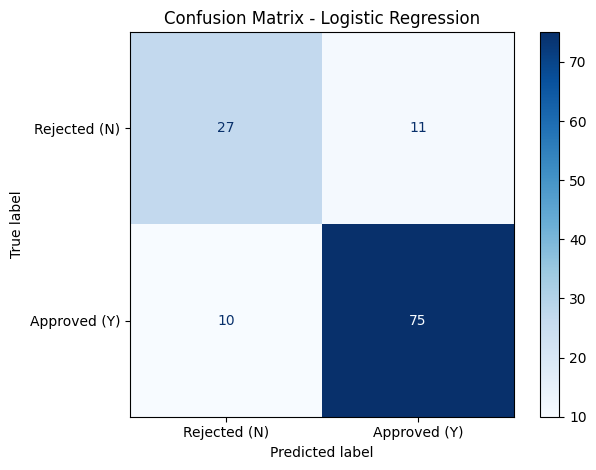

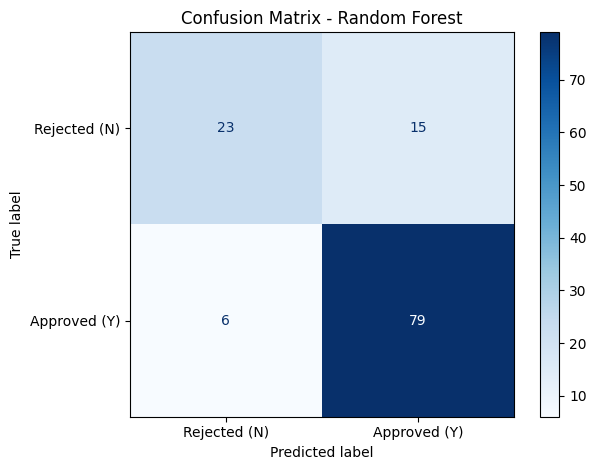

In [17]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Plot a confusion matrix for each trained model
for model_name, pipeline in models.items():

    y_pred = pipeline.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=["N", "Y"],
        display_labels=["Rejected (N)", "Approved (Y)"],
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()


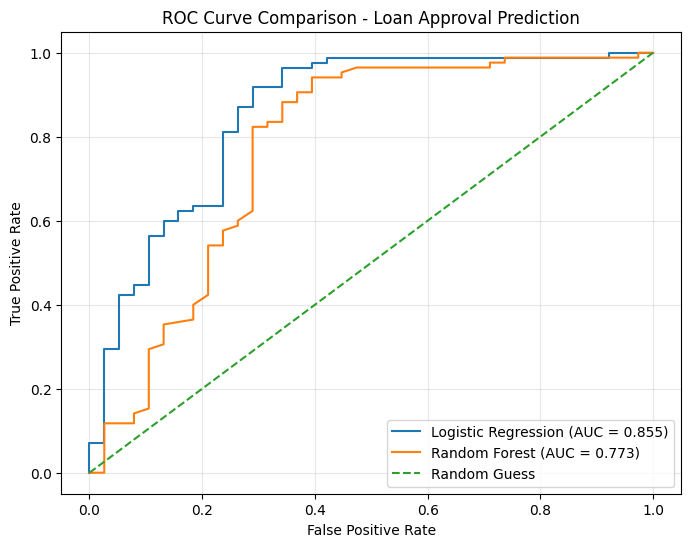

ROC curves plotted successfully!


In [19]:

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for model_name, pipeline in models.items():

    # Get probability of loan approval (Y)
    classes = list(pipeline.named_steps["classifier"].classes_)
    y_proba = pipeline.predict_proba(X_test)[:, classes.index("Y")]

    # Convert actual labels: Y = 1, N = 0
    y_true = (y_test == "Y").astype(int)

    # Calculate ROC curve
    fpr, tpr, thresholds = roc_curve(y_true, y_proba)
    roc_auc = auc(fpr, tpr)

    # Plot the curve
    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {roc_auc:.3f})"
    )

# Random guessing reference line
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")

plt.title("ROC Curve Comparison - Loan Approval Prediction")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("ROC curves plotted successfully!")



In [20]:

# Display model comparison
print("LOAN APPROVAL MODEL PERFORMANCE")
display(results_df.round(3))

# Identify the model with the highest F1-score
best_model_row = results_df.loc[results_df["F1-Score"].idxmax()]

print("\nBest model based on F1-score:")
print("Model:", best_model_row["Model"])
print("F1-score:", best_model_row["F1-Score"])
print("ROC-AUC:", best_model_row["ROC-AUC"])



LOAN APPROVAL MODEL PERFORMANCE


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.829,0.872,0.882,0.877,0.855
1,Random Forest,0.829,0.840,0.929,0.883,0.773



Best model based on F1-score:
Model: Random Forest
F1-score: 0.88268156424581
ROC-AUC: 0.7733746130030961


In [21]:

import joblib

# Select the model with the highest F1-score
best_model_name = results_df.loc[
    results_df["F1-Score"].idxmax(), "Model"
]

best_model = models[best_model_name]

# Save the complete pipeline, including preprocessing
joblib.dump(
    best_model,
    "loan_approval_model.pkl"
)

print("Best model:", best_model_name)
print("Model saved successfully as loan_approval_model.pkl")



Best model: Random Forest
Model saved successfully as loan_approval_model.pkl


In [22]:

from google.colab import files

files.download("loan_approval_model.pkl")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:

display(results_df.round(3))



,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.829,0.872,0.882,0.877,0.855
1,Random Forest,0.829,0.840,0.929,0.883,0.773
